<table style="border:0;width:100%;border-collapse:collapse"><tr style="border:0"><td style="border:0;width:105px;vertical-align:middle"><img src="../Imagenes/logo-final-ap.png" width="90"/></td><td style="border:0;vertical-align:middle"><span style="font-size:32px;font-weight:700;color:#bd232b">Aprendizaje Profundo</span></td></tr></table>

[https://github.com/AprendizajeProfundo](https://github.com/AprendizajeProfundo)

# <span style="color:#174ea6">Cuaderno 108A · Investigación de Operaciones, aprendizaje por refuerzo y coordinación inteligente</span>

**Sesión 4 · Segunda lección · 55 minutos en clase (ampliaciones para estudio autónomo)**

**Autores:** Alvaro Montenegro · Daniel Montenegro · Pilar Montenegro  
**Docente:** Alvaro Montenegro,  [ammontenegrod@gmail.com](mailto:ammontenegrod@gmail.com),  
**Institución:** Universidad de los Andes - Ecopetrol  
**Edición docente:** 108 · Octubre de 2026  
**Licencia del contenido y código originales de esta edición:** MIT (véase sección final).

> **Pregunta rectora.** ¿Qué decisiones conviene aprender de la experiencia y cuáles conviene resolver mediante optimización explícita?

**Una historia, tres puntos de inspección, decisiones pequeñas.** Todas las cifras son inventadas para aprender. Las imágenes se dibujan con Python. No se necesita Hydro-Lab para ejecutar el cuaderno.

**Al terminar:** podrás explicar por qué una ruta debe ser factible, cómo elegir visitas útiles y qué aporta RL frente a un planificador clásico.

**Fuentes directas:** programa de la sesión 4; cuadernos 103–107 como antecedentes; arquitectura G2.4 y documentación conceptual Hydro-Lab S2.11. **Este cuaderno contiene un problema didáctico reducido, no una integración ejecutada con el simulador real.**


# <span style="color:#174ea6">1. El problema, sin fórmulas</span>

Un robot sale de una base, inspecciona puntos de un oleoducto y regresa. Cada visita consume **tiempo y batería**. No puede visitar todo.

Por ahora, cada punto tiene una **prioridad estimada** (puntos de utilidad ficticios). No es una anomalía confirmada.

| Punto | Tiempo total de visita desde la base (ida, inspección y vuelta) | Prioridad estimada |
|---|---:|---:|
| A | 2 horas | 3 |
| B | 3 horas | 7 |
| C | 4 horas | 8 |

Tenemos **5 horas**. ¿Qué punto elegirías si solo podemos visitar uno? **C** tiene prioridad 8; pero si podemos combinar visitas, debemos revisar los tiempos. Estas cifras iniciales son solo para desarrollar la intuición: luego construiremos un modelo coherente de recorridos.

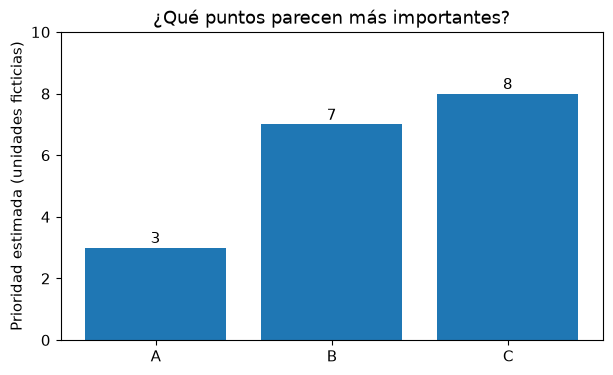

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize':(7,4),'font.size':11})
points=['A','B','C']; priority={'A':3,'B':7,'C':8}
fig,ax=plt.subplots()
ax.bar(points,[priority[p] for p in points]);ax.set_ylabel('Prioridad estimada (unidades ficticias)');ax.set_title('¿Qué puntos parecen más importantes?')
for i,p in enumerate(points):ax.text(i,priority[p]+.15,str(priority[p]),ha='center')
ax.set_ylim(0,10);plt.show()


# <span style="color:#174ea6">2. Primero: ¿qué es una ruta factible?</span>

Una **ruta** es el orden de visitas. Una ruta **factible** cumple los límites operativos. Un plan que no permite regresar a la base **no sirve**, aunque visite puntos importantes.

Para evitar cálculos geométricos, imaginemos una vía de servicio recta con base en el kilómetro 0 y puntos A, B y C en los kilómetros 1, 2 y 3. El robot recorre **1 km por hora**. Cada inspección tarda **0,5 horas**. Su autonomía máxima es **7 km** y dispone de **6 horas**. Todos los recorridos empiezan y terminan en la base.

Ejemplo: base → A → B → base recorre 1 + 1 + 2 = **4 km**; tarda 4 + 2×0,5 = **5 horas**. Es factible.

In [2]:
position={'A':1,'B':2,'C':3}
MAX_KM=7;MAX_HOURS=6;INSPECTION_HOURS=.5

def evaluate_route(route):
    locations=[0]+[position[p] for p in route]+[0]
    distance=sum(abs(b-a) for a,b in zip(locations[:-1],locations[1:]))
    hours=distance+len(route)*INSPECTION_HOURS
    useful=sum(priority[p] for p in route)
    return {'ruta':'Base → '+' → '.join(route)+' → Base' if route else 'Base → Base',
            'km':distance,'horas':hours,'prioridad_total':useful,
            'factible':distance<=MAX_KM and hours<=MAX_HOURS}
for r in [('A','B'),('B','C'),('A','B','C')]:print(evaluate_route(r))

{'ruta': 'Base → A → B → Base', 'km': 4, 'horas': 5.0, 'prioridad_total': 10, 'factible': True}
{'ruta': 'Base → B → C → Base', 'km': 6, 'horas': 7.0, 'prioridad_total': 15, 'factible': False}
{'ruta': 'Base → A → B → C → Base', 'km': 6, 'horas': 7.5, 'prioridad_total': 18, 'factible': False}


### Dibujo de las rutas (generado con Python)

El gráfico es un **esquema**, no un mapa real del oleoducto.

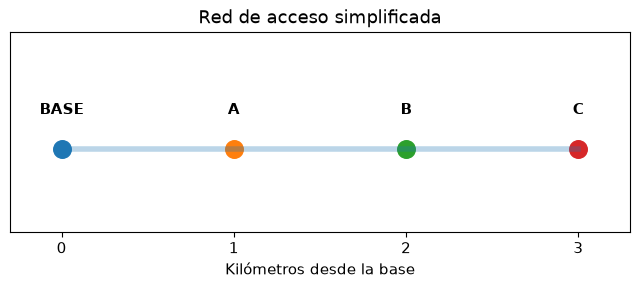

In [3]:
fig,ax=plt.subplots(figsize=(8,2.6))
ax.plot([0,3],[0,0],lw=4,alpha=.3)
for x,label in [(0,'BASE'),(1,'A'),(2,'B'),(3,'C')]:
    ax.scatter(x,0,s=160);ax.text(x,.15,label,ha='center',weight='bold')
ax.set_xlim(-.3,3.3);ax.set_ylim(-.35,.5);ax.set_xticks([0,1,2,3]);ax.set_xlabel('Kilómetros desde la base');ax.set_yticks([]);ax.set_title('Red de acceso simplificada');plt.show()


# <span style="color:#174ea6">3. Investigación de Operaciones (IO): elegir el mejor plan posible</span>

**Investigación de Operaciones** significa, aquí, comparar planes que cumplen las reglas y escoger el de mayor prioridad total.

**Paso 1:** listar las rutas posibles. **Paso 2:** calcular distancia, tiempo y prioridad. **Paso 3:** descartar las no factibles. **Paso 4:** elegir la mejor entre las restantes.

Para tres puntos podemos probar todas las combinaciones a mano o con Python. Para evitar contar dos veces la misma selección, usamos siempre el orden A–B–C.

In [7]:
routes=[comb for k in range(4) for comb in itertools.combinations(points,k)]
table=pd.DataFrame([evaluate_route(r) for r in routes])
display(table)
feasible=table[table.factible]
best=feasible.sort_values(['prioridad_total','horas'],ascending=[False,True]).iloc[0]
print('Mejor ruta factible:',best['ruta'],'| prioridad:',best['prioridad_total'])

,ruta,km,horas,prioridad_total,factible
0,Base → Base,0,0.0,0,True
1,Base → A → Base,2,2.5,3,True
2,Base → B → Base,4,4.5,7,True
3,Base → C → Base,6,6.5,8,False
4,Base → A → B → Base,4,5.0,10,True
5,Base → A → C → Base,6,7.0,11,False
6,Base → B → C → Base,6,7.0,15,False
7,Base → A → B → C → Base,6,7.5,18,False


Mejor ruta factible: Base → A → B → Base | prioridad: 10


**Pregunta:** ¿por qué no elegimos automáticamente los tres puntos? Porque una prioridad alta no autoriza incumplir el límite de tiempo.

La operación matemática, escrita después de comprenderla, es:

$$\max_{R\ \mathrm{factible}}\ \sum_{i\in R}v_i$$

Se lee: *entre las rutas permitidas, escoger la que tenga la mayor suma de prioridades*. $R$ es una ruta; $v_i$ es la prioridad estimada del punto $i$.

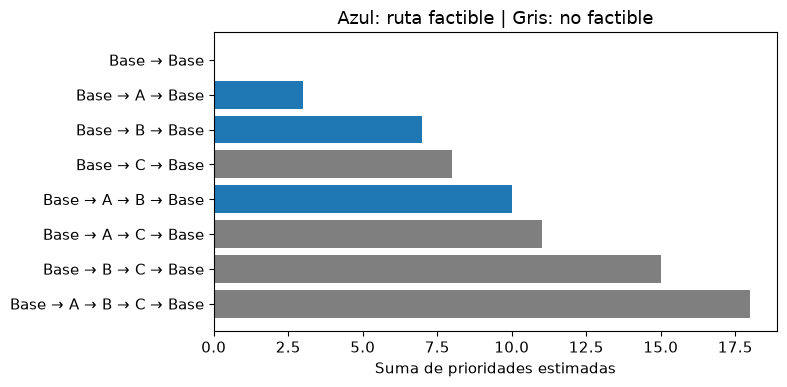

In [5]:
fig,ax=plt.subplots(figsize=(8,4))
colors=['tab:blue' if ok else 'tab:gray' for ok in table.factible]
ax.barh(table.ruta,table.prioridad_total,color=colors)
ax.invert_yaxis();ax.set_xlabel('Suma de prioridades estimadas');ax.set_title('Azul: ruta factible | Gris: no factible');plt.tight_layout();plt.show()


# <span style="color:#174ea6">4. Una prioridad no es una anomalía confirmada</span>

¿Por qué querríamos inspeccionar? Porque **no sabemos** si hay una anomalía. La inspección puede ayudar a decidir si intervenir.

Ejemplo muy pequeño: una anomalía tiene probabilidad **30 %** y, si no intervenimos, ocasionaría una pérdida de **10 unidades**. Una intervención preventiva cuesta **4 unidades**.

- No intervenir: pérdida esperada = 0,30 × 10 = **3**.
- Intervenir siempre: costo = **4**.

**Antes de inspeccionar**, conviene no intervenir (3 es menor que 4). Pero una inspección informativa podría cambiar la decisión.

La probabilidad de anomalía es una **creencia previa**, no una lectura del estado verdadero.

In [8]:
p=.30; loss=10; prevention=4
print('Costo esperado sin intervenir:',p*loss)
print('Costo de intervenir:',prevention)
print('Decisión sin inspección:', 'intervenir' if prevention<p*loss else 'no intervenir')

Costo esperado sin intervenir: 3.0
Costo de intervenir: 4
Decisión sin inspección: no intervenir



## <span style="color:#bd232b">4.1. El sensor puede equivocarse</span>

Supongamos un sensor con sensibilidad del **80 %**: si hay anomalía, informa positivo 8 de cada 10 veces. Su especificidad es **90 %**: si no hay anomalía, informa negativo 9 de cada 10 veces.

Para entenderlo, imaginemos **100 casos comparables**:

- En 30 hay anomalía: 24 positivos y 6 negativos.
- En 70 no hay anomalía: 7 positivos falsos y 63 negativos.

Si recibimos un positivo, hay 24 casos con anomalía entre 31 positivos. La probabilidad posterior es **24/31 ≈ 77,4 %**. Ya no es 30 %.

Después de un positivo, no intervenir costaría en promedio 0,774 × 10 ≈ **7,74**, más que intervenir por 4. Por eso la inspección puede cambiar la decisión.

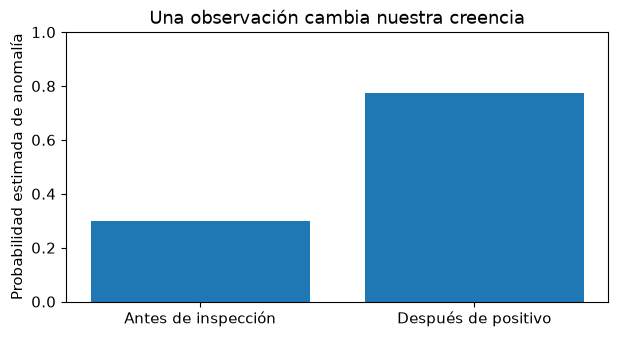

In [9]:
fig,ax=plt.subplots(figsize=(7,3.5))
ax.bar(['Antes de inspección','Después de positivo'],[.30,24/31]);ax.set_ylim(0,1)
ax.set_ylabel('Probabilidad estimada de anomalía');ax.set_title('Una observación cambia nuestra creencia');plt.show()


## <span style="color:#bd232b">4.2. ¿Cuánto vale la información?</span>

El valor de inspeccionar **no** es la probabilidad de encontrar una anomalía. Es cuánto mejora nuestra decisión gracias al resultado del sensor.

Con los 100 casos anteriores:

- Sin inspección: elegimos no intervenir; pérdida esperada por caso = **3**.
- Con inspección: intervenimos si el sensor es positivo (31 casos, costo 4 cada uno) y no intervenimos si es negativo (6 anomalías no detectadas, pérdida 10 cada una).
- Costo esperado con información = (31×4 + 6×10)/100 = **1,84**.
- Beneficio esperado de la información = 3 − 1,84 = **1,16 unidades por caso**.

**Atención:** aún falta descontar el costo de inspeccionar. Si inspeccionar cuesta 1,50, el beneficio neto es 1,16 − 1,50 = **−0,34**: no conviene inspeccionar en este ejemplo.

In [10]:
before=3.0; after=(31*4+6*10)/100; evsi=before-after
print('Costo sin información:',before,'| con información:',after)
print('Valor esperado de información:',round(evsi,2))
for inspection_cost in [.5,1.5]:print('Costo inspección',inspection_cost,'→ beneficio neto',round(evsi-inspection_cost,2))

Costo sin información: 3.0 | con información: 1.84
Valor esperado de información: 1.16
Costo inspección 0.5 → beneficio neto 0.66
Costo inspección 1.5 → beneficio neto -0.34




# <span style="color:#174ea6">5. Comparar estrategias sin hacer trampa</span>

Ahora imaginemos cuatro maneras de decidir visitas:

1. **No inspeccionar**: quedarse en la base.
2. **Calendario fijo**: visitar siempre A.
3. **Planificación IO**: elegir la ruta factible de mayor prioridad estimada.
4. **Coordinación informada**: actualizar prioridades con información observable y volver a planificar.

La cuarta alternativa **no debe conocer el estado verdadero** de las anomalías antes de actuar. Eso sería hacer trampa.

Para una comparación seria usaríamos los **mismos escenarios simulados** para todas las estrategias y registraríamos costos realizados, no solo prioridades. Este cuaderno se limita a ilustrar primero la comparación de planes con prioridades fijas.

In [11]:
fixed=('A',)
chosen=tuple(best['ruta'].replace('Base → ','').replace(' → Base','').split(' → ')) if best['ruta']!='Base → Base' else ()
comparison=pd.DataFrame([{'estrategia':'Sin inspección',**evaluate_route(())},
                         {'estrategia':'Calendario fijo',**evaluate_route(fixed)},
                         {'estrategia':'IO',**evaluate_route(chosen)}])
display(comparison[['estrategia','ruta','horas','prioridad_total','factible']])
print('Estos valores son prioridades estimadas, NO pérdidas reales evitadas.')

,estrategia,ruta,horas,prioridad_total,factible
0,Sin inspección,Base → Base,0.0,0,True
1,Calendario fijo,Base → A → Base,2.5,3,True
2,IO,Base → A → B → Base,5.0,10,True


Estos valores son prioridades estimadas, NO pérdidas reales evitadas.



# <span style="color:#174ea6">6. ¿Y dónde entra el aprendizaje por refuerzo (RL)?</span>

**IO responde:** *dadas unas prioridades y unas restricciones, ¿qué ruta puedo ejecutar?*

**RL responde:** *a partir de la experiencia, ¿cómo deberían cambiar mis decisiones cuando cambia el estado?*

Una combinación razonable es:

**Observaciones → RL propone prioridades → IO encuentra una ruta factible → robot ejecuta → llegan nuevas observaciones.**

No hace falta entrenar PPO para comprender esta arquitectura. El siguiente ejemplo usa **prioridades inventadas** para representar la salida de RL, no un agente entrenado.

In [12]:
suggested={'A':9,'B':2,'C':5}  # propuesta ilustrativa, NO aprendida
choices=[]
for r in routes:
    m=evaluate_route(r)
    if m['factible']:
        choices.append((sum(suggested[p] for p in r),r,m['horas']))
score,selected,hours=max(choices,key=lambda item:(item[0],-item[2]))
print('Prioridades propuestas:',suggested)
print('Ruta segura seleccionada por IO:',('Base',)+selected+('Base',))
print('Horas:',hours,'| prioridad propuesta acumulada:',score)

Prioridades propuestas: {'A': 9, 'B': 2, 'C': 5}
Ruta segura seleccionada por IO: ('Base', 'A', 'B', 'Base')
Horas: 5.0 | prioridad propuesta acumulada: 11



# <span style="color:#174ea6">7. ¿Qué relación tiene esto con Hydro-Lab S2.11?</span>


En Hydro-Lab S2.11, PPO controla acciones continuas asociadas a las bombas. **Este robot de inspección es un problema didáctico diferente**: aquí elegimos puntos y rutas.

No estamos afirmando que el PPO existente ya produzca prioridades del robot, ni modificamos la aplicación. Una integración real exigiría definir observaciones, acciones, costos y restricciones, y validar que no se utilice información oculta del simulador.


# <span style="color:#174ea6"> 8. Tres ejercicios muy sencillos</span>


**Ejercicio A.** Cambia `MAX_HOURS` de 6 a 5. Ejecuta de nuevo la tabla de rutas. ¿Cuál deja de ser factible?

**Ejercicio B.** Cambia la prioridad de A de 3 a 10. ¿Cambia la ruta preferida?

**Ejercicio C.** Cambia el costo de inspección de 0,5 a 1,5 en la sección 4.2. ¿Por qué una inspección informativa puede no convenir?

**Comprobación final:** ¿RL garantiza por sí solo que el robot vuelva con batería? **No.** Las restricciones deben verificarse explícitamente en el plan ejecutado.


# <span style="color:#174ea6"> 9. Para quien quiera profundizar (lectura opcional)</span>

El cuaderno original 108 también estudia grafos de acceso, rutas óptimas por enumeración, valor esperado de información con sensores imperfectos, comparación pareada de estrategias, incertidumbre de Monte Carlo y coordinación RL–IO. Aquí hemos construido **la intuición previa**, sin reproducir toda esa complejidad.

Para profundizar: Hillier y Lieberman, *Introduction to Operations Research* (rutas y restricciones); Sutton y Barto, *Reinforcement Learning: An Introduction* (políticas y aprendizaje); literatura de *orienteering problem* y *expected value of sample information* (EVSI).

**Idea para recordar:** RL puede aprender qué conviene intentar; Investigación de Operaciones ayuda a convertirlo en un plan que sí puede ejecutarse.